# Telecom Customer Churn Prediction
## CA2 Predictive Analytics / Data Science and Machine Learning

### Project goal
Explore customer churn patterns and compare five classification models.

### Workflow
1. Import libraries and load the dataset.
2. Inspect and clean the data.
3. Explore churn patterns with charts.
4. Split the data into training and testing sets.
5. Preprocess data **without using `Pipeline`**.
6. Train five models.
7. Evaluate and compare them.
8. Save charts, tables, and findings.

**Dataset:** [IBM Telco Customer Churn on Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

Run the cells from top to bottom. This notebook deliberately uses separate preprocessing steps instead of `Pipeline` so you can see what each step does.

**Important:** Preprocessing is fitted using the training data only. This helps avoid data leakage from the test set.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

pd.set_option("display.max_columns", None)

## 2. Set up folders and file paths

The notebook is inside `notebooks/`, so `..` refers to the project root.

In [2]:
project_folder = Path("..")
raw_data_path = project_folder / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
processed_folder = project_folder / "data" / "processed"
figures_folder = project_folder / "results" / "figures"
results_folder = project_folder / "results"

processed_folder.mkdir(parents=True, exist_ok=True)
figures_folder.mkdir(parents=True, exist_ok=True)
results_folder.mkdir(parents=True, exist_ok=True)

print("Dataset path:", raw_data_path.resolve())
print("Dataset exists:", raw_data_path.exists())

if not raw_data_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Put WA_Fn-UseC_-Telco-Customer-Churn.csv in data/raw/."
    )

Dataset path: C:\Users\meheb\Downloads\CA2_Telco_Churn_Beginner_Project\CA2_Telco_Churn_Beginner_Project\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset exists: True


## 3. Load the dataset

In [3]:
df = pd.read_csv(raw_data_path)

print("Dataset loaded.")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded.
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Inspect the dataset

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical Summery:")
df.describe()

print("\nMissing values detected by pandas:")
display(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nChurn counts:")
display(df["Churn"].value_counts())

print("\nChurn percentage:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Exact duplicate rows: 0

Churn counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

## 5. Clean the data

`TotalCharges` contains some blank strings. Convert it to numeric so blank strings become missing values. In this dataset, those blank values correspond to customers whose tenure is zero; after checking this, we set their total charges to zero.

In [5]:
df_clean = df.copy()

# Remove leading/trailing spaces from text columns.
text_columns = df_clean.select_dtypes(include="object").columns
for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Convert TotalCharges to a numeric column.
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

missing_total = df_clean["TotalCharges"].isna()
print("Missing TotalCharges values after conversion:", missing_total.sum())

# Only use zero when all missing TotalCharges rows have tenure equal to zero.
if (df_clean.loc[missing_total, "tenure"] == 0).all():
    df_clean.loc[missing_total, "TotalCharges"] = 0
else:
    print("Please inspect the rows with missing TotalCharges before filling them.")

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())
print("Cleaned shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("TotalCharges type:", df_clean["TotalCharges"].dtype)

Missing TotalCharges values after conversion: 11

Missing values after cleaning:


4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include="object").columns


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Cleaned shape: (7043, 21)
Duplicate rows: 0
TotalCharges type: float64


## 6. Exploratory Data Analysis (EDA)

EDA helps us identify patterns. These patterns are associations; they do not prove that one factor causes churn.

### 6.1 Overall churn distribution

,Customer Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


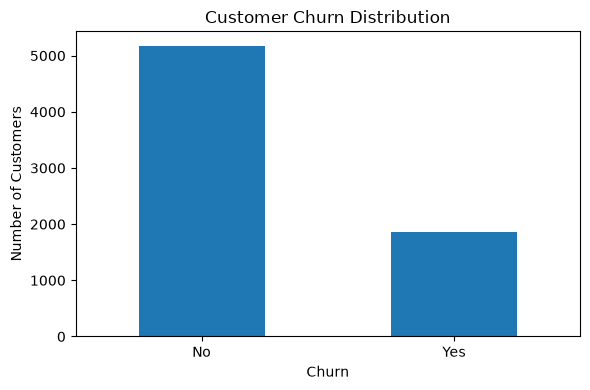

In [6]:
churn_counts = df_clean["Churn"].value_counts()
churn_percent = (df_clean["Churn"].value_counts(normalize=True) * 100).round(2)

display(pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percent
}))

ax = churn_counts.plot(kind="bar", figsize=(6, 4))
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(figures_folder / "01_churn_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Finding / Interpretation :**
The dataset contains 7,043 customers, of whom 5,174 (73.46%) stayed with the company and 1,869 (26.54%) churned. This means that approximately one in four customers left the service. The difference between the two classes indicates that the dataset is moderately imbalanced. Therefore, model evaluation should consider precision, recall, F1-score, and ROC-AUC in addition to accuracy.

### 6.2 Churn by contract type

,Total_Customers,Churned_Customers,Churn_Rate_Percent
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


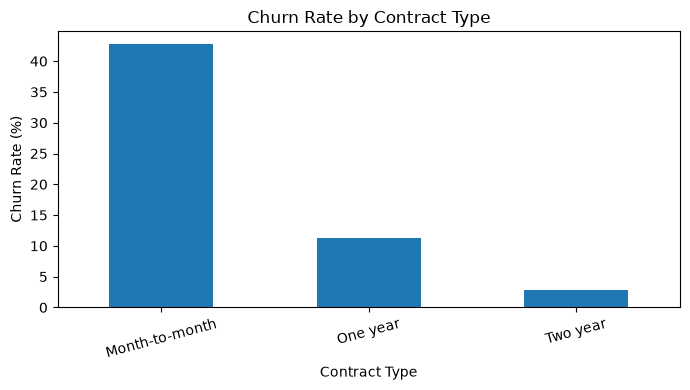

In [7]:
contract_summary = df_clean.groupby("Contract").agg(
    Total_Customers=("Churn", "size"),
    Churned_Customers=("Churn", lambda s: (s == "Yes").sum())
)
contract_summary["Churn_Rate_Percent"] = (
    contract_summary["Churned_Customers"] / contract_summary["Total_Customers"] * 100
).round(2)
display(contract_summary.sort_values("Churn_Rate_Percent", ascending=False))

ax = contract_summary["Churn_Rate_Percent"].sort_values(ascending=False).plot(
    kind="bar", figsize=(7, 4)
)
ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(figures_folder / "02_churn_by_contract.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Finding / Interpretation :**
The analysis shows that month-to-month contracts have the highest churn rate at 42.71%, followed by one-year contracts at 11.27% and two-year contracts at 2.83%. Customers with month-to-month contracts appear substantially more likely to leave than customers with longer contracts. This suggests a strong association between contract type and customer churn, although it does not prove that contract duration directly causes customers to stay.

### 6.3 Tenure by churn status

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


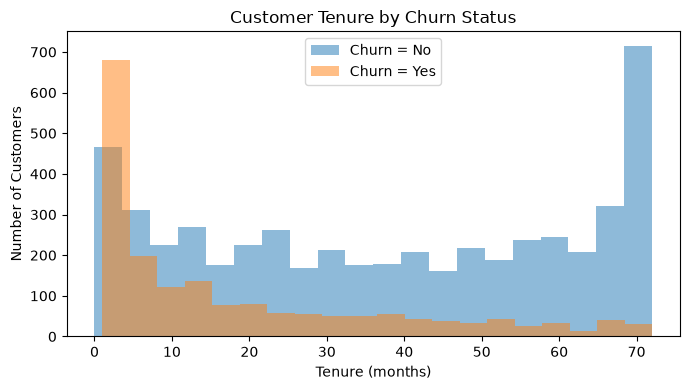

In [8]:
tenure_summary = df_clean.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)
display(tenure_summary)

plt.figure(figsize=(7, 4))
for status in ["No", "Yes"]:
    df_clean.loc[df_clean["Churn"] == status, "tenure"].plot(
        kind="hist", bins=20, alpha=0.5, label=f"Churn = {status}"
    )
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.savefig(figures_folder / "03_tenure_by_churn.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Finding / Interpretation :**
Customers who churned had an average tenure of 17.98 months and a median tenure of 10 months. In comparison, customers who stayed had an average tenure of 37.57 months and a median tenure of 38 months. The histogram also shows that churn is more concentrated among customers with shorter tenure, while many customers who remain have longer relationships with the company. This suggests that early customer retention may be an important area for further investigation.

### 6.4 Monthly and total charges by churn status

MonthlyCharges        TotalCharges         
                mean median         mean   median
Churn                                            
No             61.27  64.43      2549.91  1679.52
Yes            74.44  79.65      1531.80   703.55

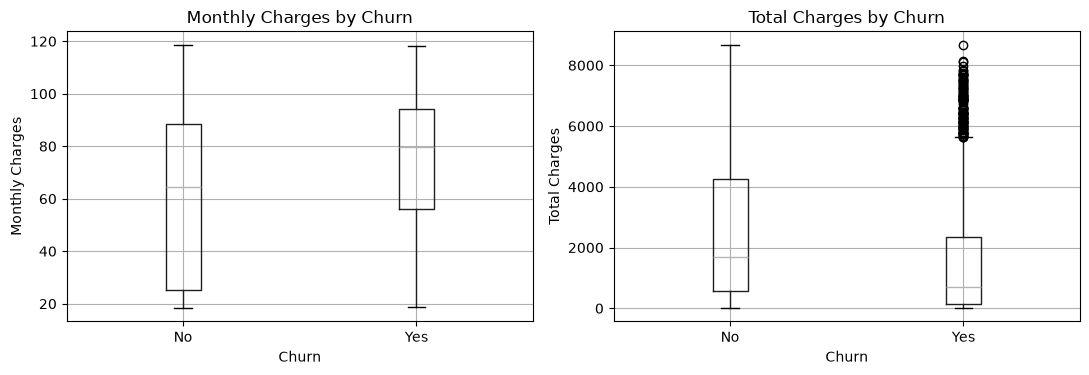

In [9]:
charges_summary = df_clean.groupby("Churn")[["MonthlyCharges", "TotalCharges"]].agg(
    ["mean", "median"]
).round(2)
display(charges_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_clean.boxplot(column="MonthlyCharges", by="Churn", ax=axes[0])
axes[0].set_title("Monthly Charges by Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Monthly Charges")

df_clean.boxplot(column="TotalCharges", by="Churn", ax=axes[1])
axes[1].set_title("Total Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Total Charges")

plt.suptitle("")
plt.tight_layout()
plt.savefig(figures_folder / "04_charges_by_churn.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Finding / Interpretation :**
Customers who churned had higher average monthly charges (74.44) than customers who stayed (61.27). However, their average total charges were lower (1,531.80 compared with 2,549.91 for customers who stayed). This pattern may partly be explained by the shorter tenure of churned customers, because customers who stay longer have more time to accumulate total charges. The results suggest that monthly charges and customer tenure are useful factors to investigate when studying churn.

### 6.5 Churn by payment method

,Total_Customers,Churned_Customers,Churn_Rate_Percent
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


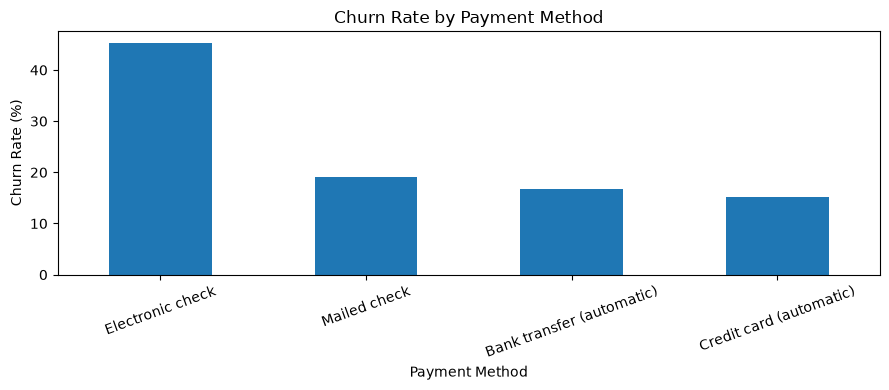

In [10]:
payment_summary = df_clean.groupby("PaymentMethod").agg(
    Total_Customers=("Churn", "size"),
    Churned_Customers=("Churn", lambda s: (s == "Yes").sum())
)
payment_summary["Churn_Rate_Percent"] = (
    payment_summary["Churned_Customers"] / payment_summary["Total_Customers"] * 100
).round(2)
display(payment_summary.sort_values("Churn_Rate_Percent", ascending=False))

ax = payment_summary["Churn_Rate_Percent"].sort_values(ascending=False).plot(
    kind="bar", figsize=(9, 4)
)
ax.set_title("Churn Rate by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(figures_folder / "05_churn_by_payment_method.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Finding / Interpretation :**
Customers using electronic checks had the highest churn rate at 45.29%, with 1,071 churned customers out of 2,365. The churn rates for mailed checks, automatic bank transfers, and automatic credit card payments were 19.11%, 16.71%, and 15.24%, respectively. Electronic-check users therefore represent a customer segment worth investigating further. However, the analysis does not establish whether the payment method itself contributes to churn or whether other customer characteristics explain the difference.

### 6.6 Churn by internet service

,Total_Customers,Churned_Customers,Churn_Rate_Percent
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40


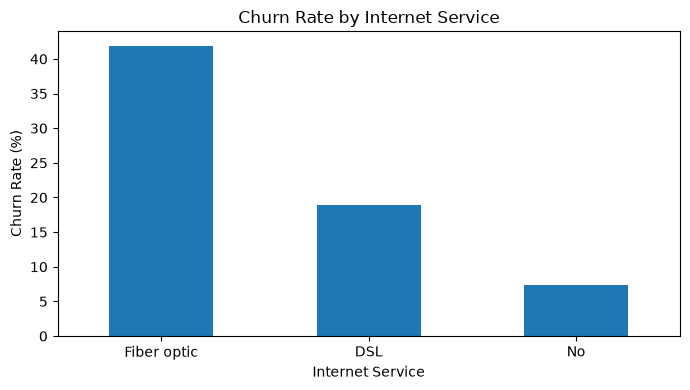

In [11]:
internet_summary = df_clean.groupby("InternetService").agg(
    Total_Customers=("Churn", "size"),
    Churned_Customers=("Churn", lambda s: (s == "Yes").sum())
)
internet_summary["Churn_Rate_Percent"] = (
    internet_summary["Churned_Customers"] / internet_summary["Total_Customers"] * 100
).round(2)
display(internet_summary.sort_values("Churn_Rate_Percent", ascending=False))

ax = internet_summary["Churn_Rate_Percent"].sort_values(ascending=False).plot(
    kind="bar", figsize=(7, 4)
)
ax.set_title("Churn Rate by Internet Service")
ax.set_xlabel("Internet Service")
ax.set_ylabel("Churn Rate (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(figures_folder / "06_churn_by_internet_service.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Finding / Interpretation :**
Fiber-optic customers had the highest churn rate at 41.89%, followed by DSL customers at 18.96%. Customers without internet service had the lowest churn rate at 7.40%. This indicates a strong association between internet service category and customer churn in the dataset. The company could investigate service quality, pricing, customer expectations, and support experiences among fiber-optic customers to understand the reasons behind this pattern. These results show an association, not proof of causation.

## 7. Save the cleaned dataset

In [12]:
cleaned_data_path = processed_folder / "telco_churn_cleaned.csv"

df_clean.to_csv(cleaned_data_path, index=False)

print("Cleaned data saved to:", cleaned_data_path.resolve())

Cleaned data saved to: 


## 8. Create features and target

We map churn to numbers (`No` = 0, `Yes` = 1). We remove `customerID` because it is an identifier. `TenureGroup` is an additional feature that groups customers by tenure.

In [13]:
df_ml = df_clean.copy()
df_ml["ChurnBinary"] = df_ml["Churn"].map({"No": 0, "Yes": 1})

df_ml["TenureGroup"] = pd.cut(
    df_ml["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

X = df_ml.drop(columns=["Churn", "ChurnBinary", "customerID"])
y = df_ml["ChurnBinary"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:")
display(y.value_counts())

Features shape: (7043, 20)
Target shape: (7043,)
Target classes:


ChurnBinary
0    5174
1    1869
Name: count, dtype: int64

## 9. Split training and testing data

We split before fitting imputers, scalers, or encoding categories. That way, preprocessing learns from the training data and does not use information from the test set.

In [15]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train_raw.shape)
print("Testing rows:", X_test_raw.shape)
print("Training churn rate (%):", round(y_train.mean() * 100, 2))
print("Testing churn rate (%):", round(y_test.mean() * 100, 2))

Training rows: (5634, 20)
Testing rows: (1409, 20)
Training churn rate (%): 26.54
Testing churn rate (%): 26.54


## 10. Preprocess the data without Pipeline

Now we'll prepare the data for machine learning.

We need to:
1. Identify numerical and categorical columns.
2. Handle missing values.
3. Scale numerical features.
4. Convert categorical features into numerical values.
5. Ensure training and testing have identical columns.

In [19]:
# Identify numerical columns
numeric_features = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns
categorical_features = X_train_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numeric_features))
print("Total categorical features:", len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']

Total numerical features: 4
Total categorical features: 16


### 10.1 — Handle missing values
We'll use SimpleImputer to fill missing values.
- Numerical columns: replace missing values with the median.
- Categorical columns: replace missing values with the most frequent value (mode).

In [20]:
from sklearn.impute import SimpleImputer

# Create separate copies of training and testing data
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

# 1. Handle missing values in numerical columns
numeric_imputer = SimpleImputer(strategy="median")

X_train[numeric_features] = numeric_imputer.fit_transform(
    X_train[numeric_features]
)

X_test[numeric_features] = numeric_imputer.transform(
    X_test[numeric_features]
)

# 2. Handle missing values in categorical columns
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train[categorical_features] = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

X_test[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

# Check missing values
print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


### 10.2 — Feature scaling
Numerical features have different ranges. For example, SeniorCitizen ranges from 0 to 1, while TotalCharges can reach thousands.

We'll use StandardScaler to standardize the numerical features.

In [21]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

# Use the same scaler on testing data
X_test[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

print("Feature scaling completed.")

print("\nTraining numerical feature means:")
print(X_train[numeric_features].mean().round(2))

print("\nTraining numerical feature standard deviations:")
print(X_train[numeric_features].std().round(2))

Feature scaling completed.

Training numerical feature means:
SeniorCitizen     0.0
tenure           -0.0
MonthlyCharges   -0.0
TotalCharges      0.0
dtype: float64

Training numerical feature standard deviations:
SeniorCitizen     1.0
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
dtype: float64


### 10.3 — Encode categorical features
Machine learning algorithms generally require numerical input. Our categorical columns contain values such as Male, Female, Month-to-month, and Electronic check.

We'll convert these categories into numerical columns using One-Hot Encoding with pd.get_dummies().

In [22]:
# Convert categorical columns into numerical columns
X_train = pd.get_dummies(
    X_train,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Make sure training and testing have identical columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Categorical encoding completed.")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nDo both datasets have the same columns?")
print(list(X_train.columns) == list(X_test.columns))

display(X_train.head())

Categorical encoding completed.

Training data shape: (5634, 34)
Testing data shape: (1409, 34)

Do both datasets have the same columns?
True


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_13-24 months,TenureGroup_25-48 months,TenureGroup_49-72 months,TenureGroup_7-12 months
3738,-0.441773,0.102371,-0.521976,-0.262257,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0
3151,-0.441773,-0.711743,0.337478,-0.503635,1,1,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0
4860,-0.441773,-0.793155,-0.809013,-0.749883,1,1,1,0,1,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,1,0,0,0
3867,-0.441773,-0.263980,0.284384,-0.172722,0,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,1,1,1,0,0,0,1,0,0
3810,-0.441773,-1.281624,-0.676279,-0.989374,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


## 11. Train five models

Each model is trained using the same processed training data. The models are stored in a dictionary so we can evaluate them in a loop.

In [23]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        metric="minkowski",
        p=2
    ),
    "Gaussian Naive Bayes": GaussianNB()
}

# Train each model and save its predictions and probabilities.
model_predictions = {}
model_probabilities = {}

#Train all models
for model_name, model in models.items():
    print("Training:", model_name)
    model.fit(X_train, y_train)

    model_predictions[model_name] = model.predict(X_test)
    model_probabilities[model_name] = model.predict_proba(X_test)[:, 1]

print("\nAll five models trained successfully.")

Training: Logistic Regression
Training: Decision Tree
Training: SVM


  warnings.warn(


Training: KNN
Training: Gaussian Naive Bayes

All five models trained successfully.


## 12. Compare model performance

Accuracy measures overall correctness. Precision measures how reliable churn alerts are. Recall measures how many actual churners are found. F1-score balances precision and recall. ROC-AUC measures ranking ability. Log loss measures probability prediction quality; lower is better.

In [25]:
# Store evaluation results
results = []

#Evaluate every trained model
for model_name in models:
    predictions = model_predictions[model_name]
    probabilities = model_probabilities[model_name]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Log Loss": log_loss(y_test, probabilities, labels=[0, 1])
    })
#Create a comparision DataFrame
results_df = pd.DataFrame(results)
#Sort models by ROC-AUC
results_df = results_df.sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
#Display results
display(results_df.round(4))
#Save the comparison table
results_csv_path = results_folder / "model_comparison.csv"
results_df.to_csv(results_csv_path, index=False)
print("Comparison table saved to:", results_csv_path.resolve())

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Log Loss
0,Logistic Regression,0.7402,0.5067,0.8048,0.6219,0.8452,0.4915
1,Decision Tree,0.7417,0.5085,0.8021,0.6224,0.8343,0.5870
2,SVM,0.7502,0.5193,0.7914,0.6271,0.8304,0.4397
3,Gaussian Naive Bayes,0.6749,0.4420,0.8556,0.5829,0.8073,2.8373
4,KNN,0.7700,0.5718,0.5321,0.5512,0.8001,0.8010


Comparison table saved to: CA2_Telco_Churn_Beginner_Project\results\model_comparison.csv


### 12.1 Chart: model score comparison

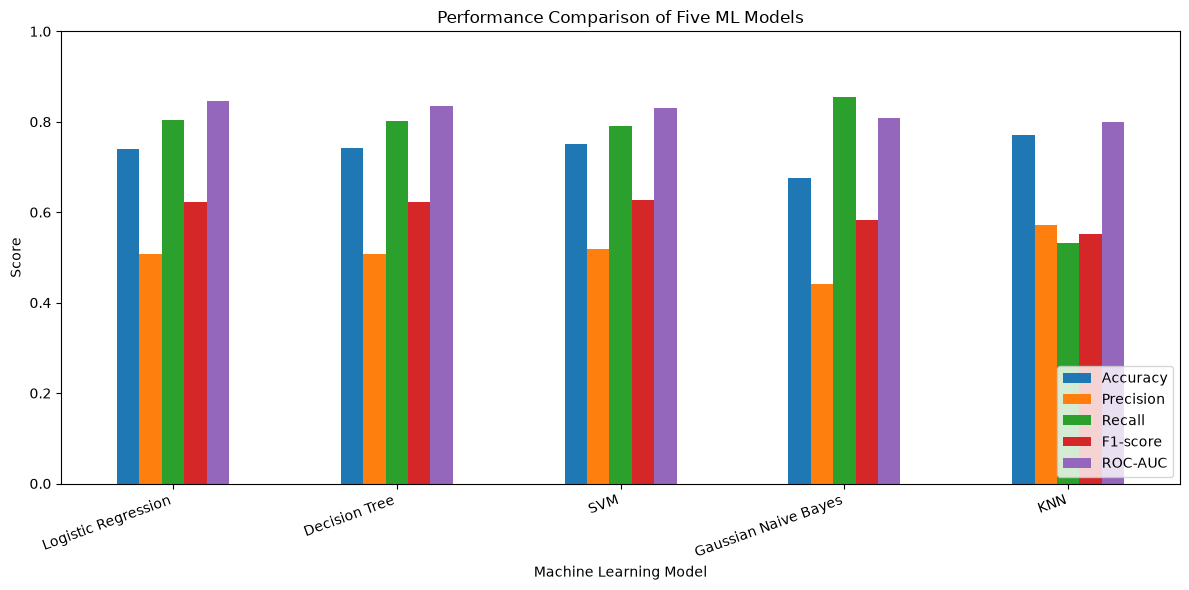

In [26]:
#Select the metrics for comartison
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
#Prepare the data for plotting
plot_df = results_df.set_index("Model")[metrics]
#Create the bar chart
ax = plot_df.plot(kind="bar", figsize=(12, 6))
ax.set_title("Performance Comparison of Five ML Models")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
#Save the chart
plt.savefig(figures_folder / "09_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Finding / Interpretation

The comparison shows that no single machine learning model performs best across all evaluation metrics. KNN achieved the highest accuracy and precision, while Logistic Regression achieved the highest ROC-AUC. SVM produced the highest F1-score and the lowest log loss, whereas Gaussian Naive Bayes achieved the highest recall.

These differences highlight the importance of selecting a model according to the business objective. In customer churn prediction, recall is important because failing to identify customers who may leave can result in lost business. However, precision must also be considered because incorrectly identifying customers as potential churners may lead to unnecessary retention costs.

## 13. Confusion matrices

The top-left cell shows correctly predicted non-churners. The top-right shows false alarms. The bottom-left shows churners missed by the model. The bottom-right shows correctly identified churners.

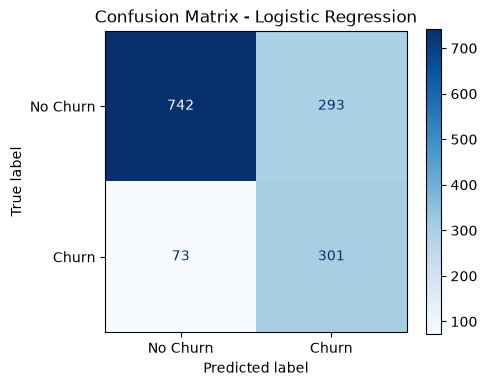

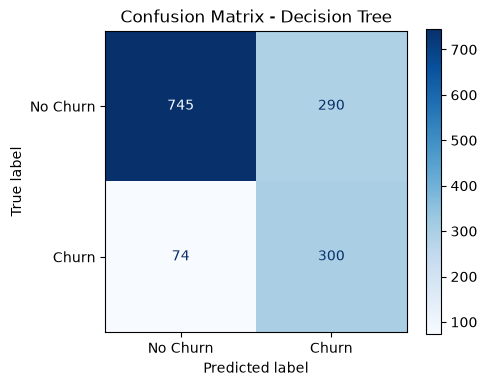

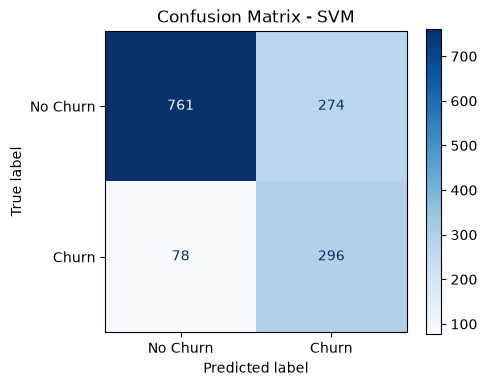

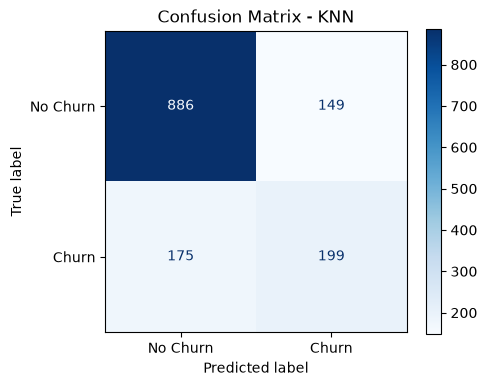

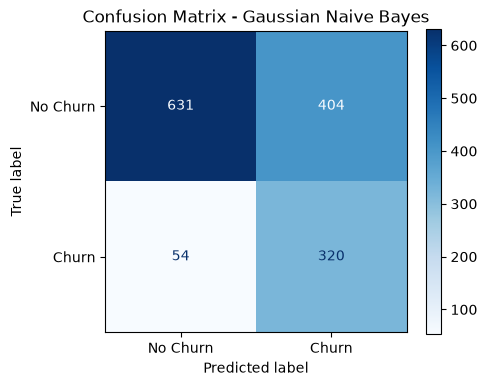

All confusion matrices saved.


In [27]:
#Generate confusion matrix for each model
for model_name, predictions in model_predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["No Churn", "Churn"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
#Create a file name for each model
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(
        figures_folder / f"confusion_matrix_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

print("All confusion matrices saved.")

### Finding / Interpretation

The confusion matrices show that the five models have different strengths and weaknesses. Gaussian Naive Bayes correctly identifies the highest number of churned customers (320) and has the fewest false negatives (54). However, it also produces 404 false positives, meaning that many customers who would stay are incorrectly classified as potential churners.

KNN correctly identifies the highest number of non-churned customers (886), but it misses 175 customers who actually churn. Logistic Regression and Decision Tree provide relatively balanced results, while SVM produces fewer false positives than Logistic Regression.

These results demonstrate the trade-off between identifying potential churners and avoiding unnecessary retention actions. The most suitable model depends on the business cost of missed churners and false alarms.

## 14. ROC curve comparison
ROC curves help us compare how well the models distinguish between churners and non-churners across different classification thresholds.

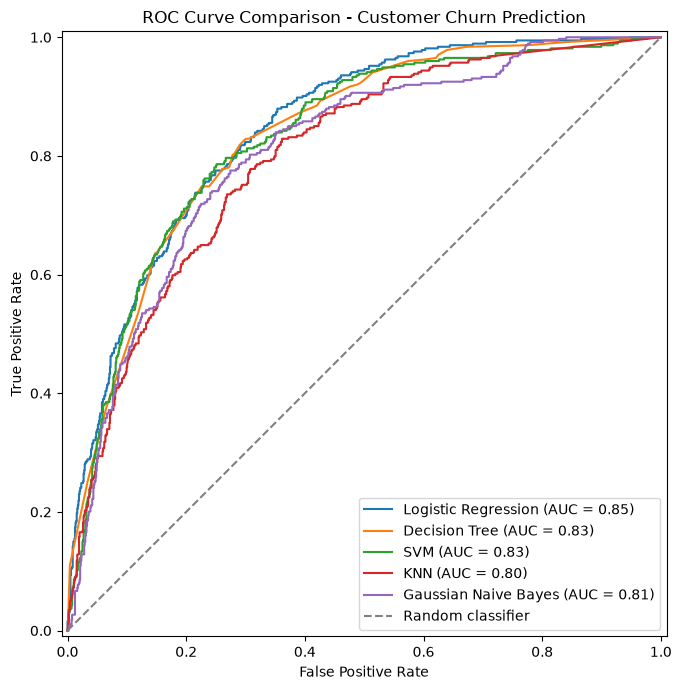

ROC curve saved.


In [28]:
#Create the figure
fig, ax = plt.subplots(figsize=(9, 7))
#Draw ROC curve for every model
for model_name, probabilities in model_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )
#Add random classifier reference llline
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("ROC Curve Comparison - Customer Churn Prediction")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
#Save the chart
plt.savefig(figures_folder / "10_roc_curve_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("ROC curve saved.")

### Finding / Interpretation

The ROC curve comparison shows that all five machine learning models perform better than a random classifier. Logistic Regression achieved the highest ROC-AUC score of 0.8452, indicating the strongest ability to distinguish between customers who churn and those who stay. Decision Tree achieved 0.8343, followed by SVM at 0.8304, Gaussian Naive Bayes at 0.8073, and KNN at 0.8001.

The results suggest that Logistic Regression provides the best overall discrimination ability among the five evaluated models. However, ROC-AUC alone should not determine the final model selection. Precision, recall, F1-score, log loss, and the business cost of incorrect predictions should also be considered.

## 15. Classification reports

In [29]:
for model_name, predictions in model_predictions.items():
    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)
    print(classification_report(
        y_test,
        predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Decision Tree
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409


SVM
              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.81      1035
       Churn       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75

### Finding / Interpretation

The classification reports show that the models perform differently when identifying customers who churn and customers who stay. Gaussian Naive Bayes achieved the highest recall for the churn class at 0.86, meaning it identified approximately 86% of actual churners. However, its precision was only 0.44, indicating a high number of false positive predictions.

KNN achieved the highest churn precision at 0.57 but had the lowest churn recall at 0.53 among the five models. SVM achieved the highest churn F1-score at approximately 0.63, providing the best balance between precision and recall.

Logistic Regression and Decision Tree also showed similar performance, with churn recall close to 0.80. Overall, the results demonstrate that model selection should depend on the business objective and the relative costs of missed churners and false positive predictions.

## 16. Generate findings from the current run

The findings below are calculated from the data and scores generated by this notebook, so they update if the preprocessing or model results change.

In [30]:
#Calculate the everall churn rate
churn_rate = (df_clean["Churn"].eq("Yes").mean() * 100)
contract_rates = contract_summary["Churn_Rate_Percent"].sort_values(ascending=False)
payment_rates = payment_summary["Churn_Rate_Percent"].sort_values(ascending=False)
internet_rates = internet_summary["Churn_Rate_Percent"].sort_values(ascending=False)

print(f"Overall churn rate: {churn_rate:.2f}%")
print("\nChurn rate by contract (%):")
display(contract_rates)
print("\nChurn rate by payment method (%):")
display(payment_rates)
print("\nChurn rate by internet service (%):")
display(internet_rates)
#Find the best model for each evaluation metric
print("\nBest model by each metric:")
for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    best_row = results_df.loc[results_df[metric].idxmax()]
    print(f"{metric}: {best_row['Model']} ({best_row[metric]:.4f})")
#Find the model with the lowest Log Loss
best_log_loss_row = results_df.loc[results_df["Log Loss"].idxmin()]
print(f"Lowest Log Loss: {best_log_loss_row['Model']} ({best_log_loss_row['Log Loss']:.4f})")

Overall churn rate: 26.54%

Churn rate by contract (%):


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn_Rate_Percent, dtype: float64


Churn rate by payment method (%):


PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn_Rate_Percent, dtype: float64


Churn rate by internet service (%):


InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn_Rate_Percent, dtype: float64


Best model by each metric:
Accuracy: KNN (0.7700)
Precision: KNN (0.5718)
Recall: Gaussian Naive Bayes (0.8556)
F1-score: SVM (0.6271)
ROC-AUC: Logistic Regression (0.8452)
Lowest Log Loss: SVM (0.4397)


### Finding / Interpretation

The analysis identified an overall customer churn rate of 26.54%, indicating that approximately one in four customers left the company.

Among contract types, month-to-month customers had the highest churn rate at 42.71%. Electronic-check users had the highest churn rate among payment methods at 45.29%, while fiber-optic customers had the highest churn rate among internet service categories at 41.89%.

The model comparison showed that no single model performed best across all evaluation metrics. KNN achieved the highest accuracy (0.7700) and precision (0.5718), while Gaussian Naive Bayes achieved the highest recall (0.8556). SVM produced the highest F1-score (0.6271) and the lowest log loss (0.4397). Logistic Regression achieved the highest ROC-AUC (0.8452).

These findings suggest that customer retention strategies should pay particular attention to month-to-month customers and the identified high-churn segments. Model selection should also consider the business impact of false positives and missed churners rather than relying only on accuracy.

## 17. Project Interpretation, Business Recommendations, and Limitations

### 17.1 Overall Project Findings

The analysis of 7,043 telecom customers revealed an overall churn rate of 26.54%, meaning that approximately one in four customers left the company.

The exploratory data analysis identified several important patterns:

- **Contract Type:** Month-to-month customers had the highest churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
- **Payment Method:** Customers using electronic checks had the highest churn rate at 45.29%.
- **Internet Service:** Fiber-optic customers had the highest churn rate at 41.89%.
- **Customer Tenure:** Customers who churned had an average tenure of 17.98 months, compared with 37.57 months for customers who stayed.
- **Monthly Charges:** Churned customers had higher average monthly charges (74.44) than customers who stayed (61.27).

These findings suggest that contract type, payment method, internet service, tenure, and monthly charges are useful factors to investigate when studying customer churn.

### 17.2 Machine Learning Model Findings

Five classification algorithms were trained and evaluated: Logistic Regression, Decision Tree, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Gaussian Naive Bayes.

The model comparison produced the following important results:

- **KNN** achieved the highest accuracy of 77.00% and precision of 57.18%.
- **Gaussian Naive Bayes** achieved the highest recall of 85.56%, identifying the largest proportion of actual churners.
- **SVM** achieved the highest F1-score of 62.71% and the lowest log loss of 0.4397.
- **Logistic Regression** achieved the highest ROC-AUC of 0.8452.

No single model performed best across all evaluation metrics. Logistic Regression and SVM showed relatively balanced performance, while Gaussian Naive Bayes prioritized identifying more actual churners at the cost of more false positive predictions.

### 17.3 Business Recommendations

Based on the observed patterns, the following recommendations could be considered:

1. **Improve early customer retention:** Provide better onboarding, support, and engagement for customers during their initial months.
2. **Review month-to-month contracts:** Investigate suitable loyalty benefits or longer-contract options to improve customer retention.
3. **Investigate electronic-check payments:** Examine whether payment-related difficulties or other customer characteristics are associated with the higher churn rate.
4. **Review fiber-optic services:** Investigate service quality, pricing, customer complaints, and customer expectations.
5. **Evaluate pricing strategies:** Study whether monthly charges influence customer satisfaction and retention.
6. **Use predictive models for retention planning:** Consider testing models to identify customers who may be at risk of leaving, followed by targeted retention experiments.

These recommendations should be tested and evaluated before being implemented on a large scale.

### 17.4 Limitations

- The project uses a single telecom customer dataset.
- Model evaluation is based on one 80:20 train-test split.
- Model performance may differ when applied to new customer data.
- The observed relationships do not establish cause-and-effect relationships.
- Classification thresholds influence precision and recall.
- The models have not been tested in a real business environment.
- Further validation and cost analysis are required before practical deployment.

### 17.5 Conclusion

This project demonstrates the use of data cleaning, exploratory data analysis, feature engineering, data preprocessing, and machine learning classification techniques to study and predict telecom customer churn.

The analysis identified important customer segments associated with higher churn, particularly month-to-month contract customers, electronic-check users, and fiber-optic customers.

Five machine learning models were developed and evaluated using accuracy, precision, recall, F1-score, ROC-AUC, log loss, confusion matrices, and ROC curves.

Among the evaluated models, Logistic Regression achieved the highest ROC-AUC, SVM achieved the highest F1-score, and Gaussian Naive Bayes achieved the highest recall. These results demonstrate that model selection depends on the objective and the costs associated with different prediction errors.

Overall, the project provides a foundation for understanding customer churn and exploring data-driven customer retention strategies. Further testing and validation would be necessary before deploying these models in a real-world business environment.

## 18. Final output file check

In [33]:
required_files = [
    processed_folder / "telco_churn_cleaned.csv",
    results_folder / "model_comparison.csv",

    figures_folder / "01_churn_distribution.png",
    figures_folder / "02_churn_by_contract.png",
    figures_folder / "03_tenure_by_churn.png",
    figures_folder / "04_charges_by_churn.png",
    figures_folder / "05_churn_by_payment_method.png",
    figures_folder / "06_churn_by_internet_service.png",

    figures_folder / "09_model_comparison.png",
    figures_folder / "10_roc_curve_comparison.png",

    figures_folder / "confusion_matrix_logistic_regression.png",
    figures_folder / "confusion_matrix_decision_tree.png",
    figures_folder / "confusion_matrix_svm.png",
    figures_folder / "confusion_matrix_knn.png",
    figures_folder / "confusion_matrix_gaussian_naive_bayes.png"
]

missing_files = []

for file_path in required_files:

    if file_path.exists():
        print("FOUND  ", file_path)
    else:
        print("MISSING", file_path)
        missing_files.append(file_path)

print("\nTotal required files:", len(required_files))
print("Missing files:", len(missing_files))

if len(missing_files) == 0:
    print("\nAll project outputs are available!")
else:
    print("\nPlease check the missing files.")

FOUND   ..\data\processed\telco_churn_cleaned.csv
FOUND   ..\results\model_comparison.csv
FOUND   ..\results\figures\01_churn_distribution.png
FOUND   ..\results\figures\02_churn_by_contract.png
FOUND   ..\results\figures\03_tenure_by_churn.png
FOUND   ..\results\figures\04_charges_by_churn.png
FOUND   ..\results\figures\05_churn_by_payment_method.png
FOUND   ..\results\figures\06_churn_by_internet_service.png
FOUND   ..\results\figures\09_model_comparison.png
FOUND   ..\results\figures\10_roc_curve_comparison.png
FOUND   ..\results\figures\confusion_matrix_logistic_regression.png
FOUND   ..\results\figures\confusion_matrix_decision_tree.png
FOUND   ..\results\figures\confusion_matrix_svm.png
FOUND   ..\results\figures\confusion_matrix_knn.png
FOUND   ..\results\figures\confusion_matrix_gaussian_naive_bayes.png

Total required files: 15
Missing files: 0

All project outputs are available!
